# Diabetes Risk Factor Analysis
**HSE 751 Programming for Health Data Science, Reproducibility Exercise**
**Author:** Jeremy Childress

## 1. Purpose and Overview

This notebook describes how common clinical measurements differ between female patients with and without diabetes in the Pima Indians Diabetes dataset. It is written so that a data science team at another site can run it start to finish without outside help, and reuse it as a template for their own patient data.

**Workflow**

| Section | What happens |
|---|---|
| 2. Setup | Install and import packages, record versions, set the random seed |
| 3. Data source | Where the data comes from and what each column means |
| 4. Data loading | Load the CSV, with an upload prompt if it is missing |
| 5. Data validation | Stop the run if the file is not the expected dataset |
| 6. Data preparation | Recode impossible zero values as missing |
| 7. Analysis | Descriptive statistics, plots, correlation, two inferential tests |
| 8. Results | Seeded sampling checks and a summary table of key results |
| 9. Conclusions | Main findings and limitations |

**How to run:** upload `Example Dataset_Diabetes.csv` to the same folder as this notebook (in Colab, the Files pane on the left), then choose **Runtime > Restart session and run all**. No other steps are needed.

## 2. Setup and Environment

The cell below installs the packages this notebook needs. Google Colab already has all of them, so on Colab the install line finishes quickly. On a local machine it installs anything missing.

The minimum versions are listed in `requirements.txt` in the project repository. The cell also prints the exact versions in use, so results can be compared across sites.

In [1]:
# Install required packages (already present on Google Colab)
!pip install -q "pandas>=2.0" "numpy>=1.24" "matplotlib>=3.7" "seaborn>=0.12" "scipy>=1.10"

In [2]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import ttest_ind, mannwhitneyu

# One seed for every random step so results are the same on every run
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scipy:", scipy.__version__)

Python: 3.13.15
pandas: 2.2.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
scipy: 1.16.3


## 3. Data Source and Provenance

| Item | Detail |
|---|---|
| Dataset | Pima Indians Diabetes Database |
| Original source | National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK) |
| Public distribution | UCI Machine Learning Repository and Kaggle (CC0 public domain) |
| Project copy | `Example Dataset_Diabetes.csv`, from the HSE 751 course GitHub repository, `Reproducibility Exercise` folder |
| Population | 768 female patients of Pima Indian heritage, age 21 or older |
| Size | 768 rows, 9 columns |
| Role in project | Teaching dataset used to build a reusable diabetes risk factor workflow |

The course copy uses shortened column names. Compared with the public version, `BloodPressure` is `D_BP`, `SkinThickness` is `Skin_Thickness`, and `DiabetesPedigreeFunction` is `Pedigree`.

| Column | Meaning | Unit |
|---|---|---|
| Pregnancies | Number of pregnancies | count |
| Glucose | Plasma glucose, 2 hours into an oral glucose tolerance test | mg/dL |
| D_BP | Diastolic blood pressure | mm Hg |
| Skin_Thickness | Triceps skinfold thickness | mm |
| Insulin | 2-hour serum insulin | mu U/mL |
| BMI | Body mass index | kg/m² |
| Pedigree | Diabetes pedigree function, a family history score | score |
| Age | Age | years |
| Outcome | Diabetes diagnosis, 1 = yes, 0 = no | binary |

**Note for receiving sites:** to run this workflow on your own data, rename your columns to match the table above and update `DATA_FILE` in Section 4.

## 4. Data Loading

The original notebook loaded the file from `/content/`, which only exists on Google Colab. The function below looks for the file in the current working folder instead. If the file is not there and the notebook is running on Colab, it opens an upload prompt. Anywhere else, it stops with a clear message.

**Action required:** if an upload button appears below, select `Example Dataset_Diabetes.csv`.

In [3]:
DATA_FILE = "Example Dataset_Diabetes.csv"


def load_data(path):
    """Load the diabetes CSV."""
    if not os.path.exists(path):
        try:
            from google.colab import files
            print(f"'{path}' not found.")
            files.upload()
        except ImportError:
            raise FileNotFoundError(
                f"'{path}' was not found."
            )
    return pd.read_csv(path)


df_raw = load_data(DATA_FILE)
print("Loaded", DATA_FILE)
df_raw.head()

Loaded Example Dataset_Diabetes.csv


,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 5. Data Validation

Before any cleaning, these checks confirm the right file was loaded. If any check fails, the notebook stops with a message saying what is wrong. Continuing with the wrong file would give results that look normal but are not.

The checks cover the column names, the row count, the outcome coding, the data types, and true missing values.

In [4]:
EXPECTED_COLUMNS = ["Pregnancies", "Glucose", "D_BP", "Skin_Thickness",
                    "Insulin", "BMI", "Pedigree", "Age", "Outcome"]
EXPECTED_ROWS = 768


def validate_data(df):
    """Stop the run if the data does not match the expected diabetes dataset."""
    assert list(df.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {list(df.columns)}"
    assert len(df) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS} rows, found {len(df)}"
    assert set(df["Outcome"].unique()) == {0, 1}, "Outcome must contain only 0 and 1"

    for col in EXPECTED_COLUMNS:
        assert pd.api.types.is_numeric_dtype(df[col]), f"{col} is not numeric"

    print("All validation checks passed.")
    print("Shape:", df.shape)
    print("\nMissing values (NaN):")
    print(df.isna().sum())


validate_data(df_raw)

All validation checks passed.
Shape: (768, 9)

Missing values (NaN):
Pregnancies       0
Glucose           0
D_BP              0
Skin_Thickness    0
Insulin           0
BMI               0
Pedigree          0
Age               0
Outcome           0
dtype: int64


The file has no NaN values, but that does not mean it has no missing data. The next check counts zeros. A zero is valid for `Pregnancies` and `Outcome`, but not for glucose, blood pressure, skin thickness, insulin, or BMI. In this dataset, zeros in those columns stand in for measurements that were never taken.

In [5]:
print("Zero values per column:")
print((df_raw == 0).sum())

Zero values per column:
Pregnancies       111
Glucose             5
D_BP               35
Skin_Thickness    227
Insulin           374
BMI                11
Pedigree            0
Age                 0
Outcome           500
dtype: int64


## 6. Data Preparation

**Decision: recode impossible zeros as missing (NaN).** A living patient cannot have a glucose, blood pressure, or BMI of 0. Leaving them as zeros pulls averages down and weakens comparisons between groups.

**Decision: keep all rows rather than dropping incomplete ones.** Insulin alone is missing for 374 of 768 patients. Dropping every incomplete row would discard about half the data. Each analysis below uses the patients who have values for the variables involved.

The raw data in `df_raw` is never changed. All later steps use the prepared copy `df`.

In [6]:
# Columns where a value of 0 is not physiologically possible
ZERO_AS_MISSING = ["Glucose", "D_BP", "Skin_Thickness", "Insulin", "BMI"]


def prepare_data(df, columns):
    """Return a copy of the data with zeros in the given columns set to NaN."""
    df_clean = df.copy()
    for col in columns:
        df_clean[col] = df_clean[col].replace(0, np.nan)
    return df_clean


df = prepare_data(df_raw, ZERO_AS_MISSING)

print("Missing values after preparation:")
print(df.isna().sum())

Missing values after preparation:
Pregnancies         0
Glucose             5
D_BP               35
Skin_Thickness    227
Insulin           374
BMI                11
Pedigree            0
Age                 0
Outcome             0
dtype: int64


## 7. Analysis

### 7.1 Descriptive Statistics

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,763.0,121.69,30.54,44.00,99.00,117.00,141.00,199.00
D_BP,733.0,72.41,12.38,24.00,64.00,72.00,80.00,122.00
Skin_Thickness,541.0,29.15,10.48,7.00,22.00,29.00,36.00,99.00
Insulin,394.0,155.55,118.78,14.00,76.25,125.00,190.00,846.00
BMI,757.0,32.46,6.92,18.20,27.50,32.30,36.60,67.10
Pedigree,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


### Mean and Standard Deviation

The sample mean summarizes the typical value of a measurement across patients:

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i
$$

The sample standard deviation summarizes how spread out patients are around that mean:

$$
s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}
$$

where $x_i$ is the value for patient $i$, $\bar{x}$ is the sample mean, and $n$ is the number of patients with a recorded value for that variable. After preparation, $n$ differs by column. It is 763 for Glucose, 757 for BMI, and only 394 for Insulin.

**What these show in this dataset.** The average patient has a 2-hour glucose of about 121.7 mg/dL (SD 30.5) and a BMI of about 32.5 (SD 6.9), which falls in the obese range. Age has a mean of 33.2 but a median of 29, so the sample is young with a smaller group of older patients. Insulin varies the most (mean 155.6, SD 118.8, max 846), and its SD is close to its mean. That points to a strongly right-skewed variable, where the mean alone is a poor summary. This is one reason the later tests use methods that do not assume normal data.

The table below compares means and SDs by diabetes status.

In [8]:
def summarize_by_outcome(df, columns):
    """Return the mean and standard deviation of each column for each Outcome group."""
    return df.groupby("Outcome")[columns].agg(["mean", "std"]).round(2).T


KEY_VARIABLES = ["Glucose", "BMI", "Age", "Insulin", "D_BP"]
summarize_by_outcome(df, KEY_VARIABLES)

Outcome            0       1
Glucose mean  110.64  142.32
        std    24.78   29.60
BMI     mean   30.86   35.41
        std     6.56    6.61
Age     mean   31.19   37.07
        std    11.67   10.97
Insulin mean  130.29  206.85
        std   102.48  132.70
D_BP    mean   70.88   75.32
        std    12.16   12.30

Patients with diabetes have higher averages on every key variable. The gap is largest for glucose, at 142.3 vs 110.6 mg/dL. BMI is 35.4 vs 30.9, and age is 37.1 vs 31.2 years. Section 7.4 tests whether these gaps are larger than chance would explain.

### 7.2 Visualizations

**Single-variable distributions.** Glucose and BMI are the two variables most often linked to diabetes risk.

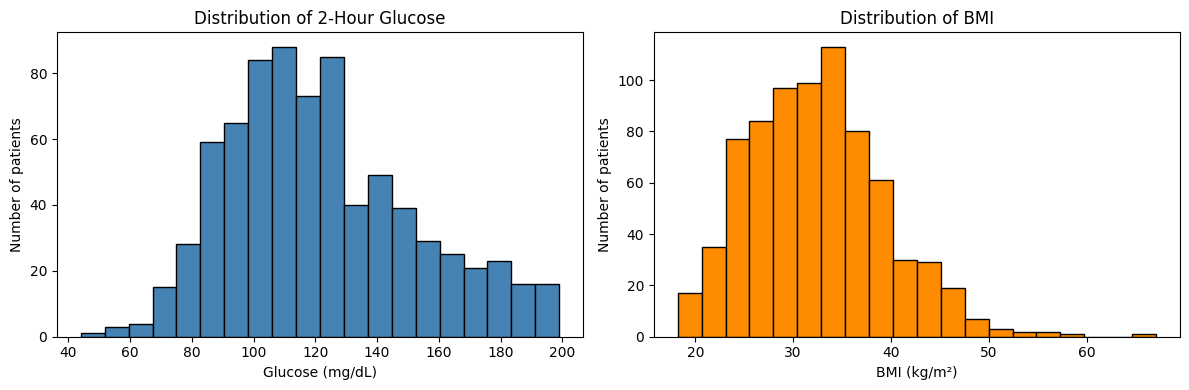

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Glucose"].dropna(), bins=20, color="steelblue", edgecolor="black")
axes[0].set_title("Distribution of 2-Hour Glucose")
axes[0].set_xlabel("Glucose (mg/dL)")
axes[0].set_ylabel("Number of patients")

axes[1].hist(df["BMI"].dropna(), bins=20, color="darkorange", edgecolor="black")
axes[1].set_title("Distribution of BMI")
axes[1].set_xlabel("BMI (kg/m²)")
axes[1].set_ylabel("Number of patients")

plt.tight_layout()
plt.show()

Both are roughly bell-shaped once the zeros are removed. BMI has a right tail out to 67.

**Bivariate 1: glucose by diabetes status.** A boxplot compares a continuous variable across the two outcome groups.

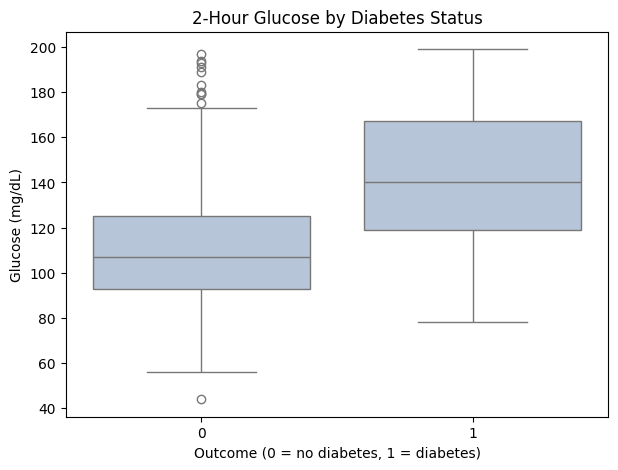

In [10]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Outcome", y="Glucose", color="lightsteelblue")
plt.title("2-Hour Glucose by Diabetes Status")
plt.xlabel("Outcome (0 = no diabetes, 1 = diabetes)")
plt.ylabel("Glucose (mg/dL)")
plt.show()

Median glucose is about 140 mg/dL in the diabetes group and 107 in the non-diabetes group. Most of the diabetes group sits above the non-diabetes median. The boxes still overlap, so glucose alone will not perfectly separate patients with and without diabetes.

**Bivariate 2: glucose vs BMI, colored by diabetes status.** A scatter plot shows how two continuous risk factors relate, and where diabetes cases fall.

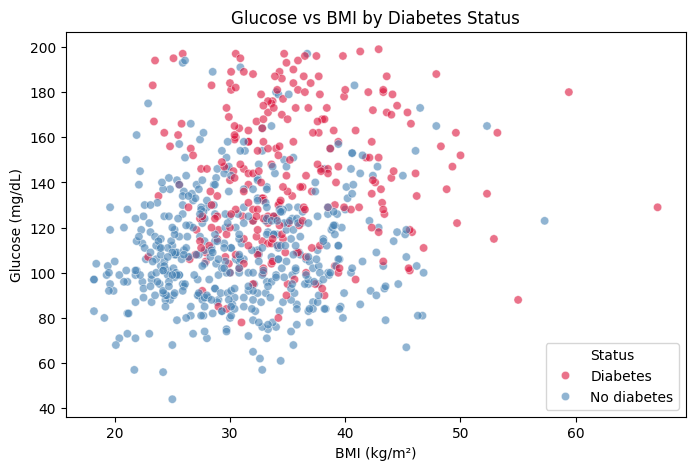

In [11]:
# Readable labels for the legend (plotting copy only, df is unchanged)
plot_df = df.assign(Status=df["Outcome"].map({0: "No diabetes", 1: "Diabetes"}))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_df, x="BMI", y="Glucose", hue="Status",
                palette={"No diabetes": "steelblue", "Diabetes": "crimson"}, alpha=0.6)
plt.title("Glucose vs BMI by Diabetes Status")
plt.xlabel("BMI (kg/m²)")
plt.ylabel("Glucose (mg/dL)")
plt.show()

Diabetes cases (red) cluster in the upper right, where both glucose and BMI are high. Below a BMI of about 25, there are few cases at any glucose level. Glucose and BMI are only weakly related to each other (Spearman ρ = 0.23, below), so they carry mostly separate information about risk.

### 7.3 Correlation Matrix

**Method: Spearman rank correlation.** Pearson correlation assumes linear relationships between roughly normal variables. Several variables here are skewed (Insulin, Pedigree, Age), Pregnancies is a count, and Outcome is binary. Spearman works on ranks, so it handles skew and outliers and only assumes the relationship moves in one direction. Phi_K was also considered, but it needs an extra package and adds little for this all-numeric dataset.

Correlations are computed on the prepared data, using each pair of variables where both values are present.

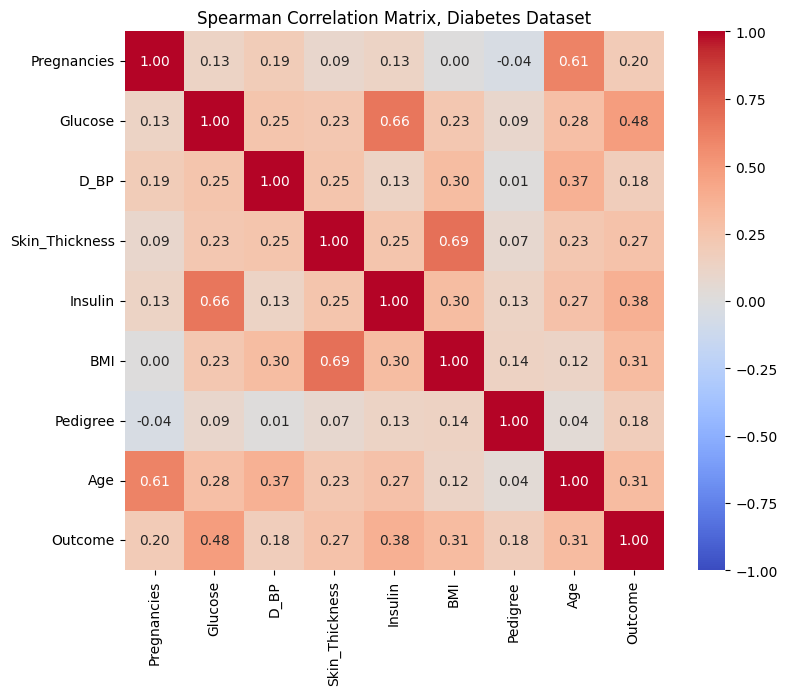

In [12]:
spearman_corr = df.corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Spearman Correlation Matrix, Diabetes Dataset")
plt.show()

**Key relationships**

- **Glucose and Outcome (ρ = 0.48)** is the strongest correlation with diabetes status. It is moderate and positive, which fits glucose being the main diagnostic measure.
- **Insulin and Glucose (ρ = 0.66)** is strong and positive. This is expected, since the body releases insulin in response to glucose. Insulin is also missing for about half of patients, so this estimate rests on fewer people.
- **BMI and Skin_Thickness (ρ = 0.69)** is the strongest pair overall. Both measure body fat, so they partly duplicate each other. That matters for future models, where using both may add little.
- **Age and Pregnancies (ρ = 0.61)** is strong and positive, and simply reflects that older women have had more time for pregnancies.
- **BMI (0.31) and Age (0.31)** are both moderately linked to Outcome.
- Pedigree is only weakly linked to everything (ρ ≤ 0.18), including Outcome.

These are associations only. They do not show that any variable causes diabetes.

### 7.4 Inferential Analysis

**Test 1: Welch's two-sample t-test, glucose by diabetes status.**

Purpose: test whether mean 2-hour glucose differs between patients with and without diabetes.

$$
H_0: \mu_{\text{diabetes}} = \mu_{\text{no diabetes}}
\qquad
H_1: \mu_{\text{diabetes}} \neq \mu_{\text{no diabetes}}
$$

$$
t = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_0^2}{n_0}}}
$$

where $\bar{x}$, $s$, and $n$ are the mean, standard deviation, and sample size of glucose in each group (1 = diabetes, 0 = no diabetes).

**Two changes from the original analysis.** First, the original test included the 5 patients with glucose recorded as 0. Those are now missing. Second, the original used the standard t-test, which assumes equal variances. The diabetes group's SD is 29.6 vs 24.8, so this version uses Welch's t-test (`equal_var=False`), which does not need that assumption.

In [13]:
def compare_groups(df, column):
    """Split one column by Outcome and return the two groups, dropping missing values."""
    no_diabetes = df.loc[df["Outcome"] == 0, column].dropna()
    diabetes = df.loc[df["Outcome"] == 1, column].dropna()
    return no_diabetes, diabetes


glucose_0, glucose_1 = compare_groups(df, "Glucose")
t_stat, t_p = ttest_ind(glucose_1, glucose_0, equal_var=False)

print(f"n (no diabetes) = {len(glucose_0)}, n (diabetes) = {len(glucose_1)}")
print(f"Mean glucose: {glucose_0.mean():.1f} vs {glucose_1.mean():.1f} mg/dL")
print(f"t = {t_stat:.2f}, p = {t_p:.2e}")

n (no diabetes) = 497, n (diabetes) = 266
Mean glucose: 110.6 vs 142.3 mg/dL
t = 14.88, p = 2.84e-41


**Interpretation.** Mean glucose is 142.3 mg/dL in the diabetes group (n = 266) and 110.6 mg/dL in the non-diabetes group (n = 497), a difference of about 32 mg/dL. With t = 14.9 and p far below 0.05, we reject $H_0$. Glucose is clearly higher on average in patients with diabetes.

**Test 2: Mann-Whitney U test, BMI by diabetes status.**

Purpose: test whether BMI tends to be higher in patients with diabetes. The Mann-Whitney U test compares the two groups by rank, so it does not assume BMI is normally distributed. That suits BMI here because of its right tail.

$$
H_0: P(X_1 > X_0) = 0.5
\qquad
H_1: P(X_1 > X_0) \neq 0.5
$$

$$
U = \sum_{i=1}^{n_1}\sum_{j=1}^{n_0} S(X_{1i}, X_{0j}),
\qquad
S(a, b) =
\begin{cases}
1 & a > b \\
\tfrac{1}{2} & a = b \\
0 & a < b
\end{cases}
$$

where $X_{1i}$ is the BMI of patient $i$ with diabetes and $X_{0j}$ is the BMI of patient $j$ without diabetes. $U$ counts how often a diabetes patient has the higher BMI across every possible pair. Dividing $U$ by $n_1 n_0$ gives the probability that a randomly chosen diabetes patient has a higher BMI than a randomly chosen non-diabetes patient.

In [14]:
bmi_0, bmi_1 = compare_groups(df, "BMI")
u_stat, u_p = mannwhitneyu(bmi_1, bmi_0, alternative="two-sided")
prob_higher = u_stat / (len(bmi_1) * len(bmi_0))

print(f"n (no diabetes) = {len(bmi_0)}, n (diabetes) = {len(bmi_1)}")
print(f"Median BMI: {bmi_0.median():.1f} vs {bmi_1.median():.1f}")
print(f"U = {u_stat:.0f}, p = {u_p:.2e}")
print(f"P(diabetes patient has higher BMI) = {prob_higher:.2f}")

n (no diabetes) = 491, n (diabetes) = 266
Median BMI: 30.1 vs 34.3
U = 89731, p = 1.82e-17
P(diabetes patient has higher BMI) = 0.69


**Interpretation.** Median BMI is 34.3 in the diabetes group and 30.1 in the non-diabetes group. The test is significant (p far below 0.05), so we reject $H_0$. A randomly chosen patient with diabetes has a higher BMI than a randomly chosen patient without diabetes about 69% of the time. That is a meaningful shift, but not a clean separation, which matches the overlap in the scatter plot.

### 7.5 Framing the Data as a Classification Problem

This section shows how the dataset would be set up for the supervised machine learning work in later weeks. No model is fit in this notebook.

The dataset is a set of patients, each with predictor values and a diabetes label:

$$
\mathcal{D} = \{(x_i, y_i)\}_{i=1}^{n},
\qquad
n = 768,
\qquad
x_i \in \mathbb{R}^{8},
\qquad
y_i \in \{0, 1\}
$$

where:

- $\mathcal{D}$ is the full diabetes dataset.
- $n = 768$ is the number of patients (rows).
- $i$ indexes one patient, $i = 1, 2, \ldots, 768$.
- $x_i$ is the vector of 8 clinical predictors for patient $i$.
- $p = 8$ is the number of predictors. `Outcome` is the label, not a predictor, so it is not counted.
- $y_i$ is the `Outcome` value for patient $i$. It is 0 for no diabetes and 1 for diabetes, making this a **binary classification** problem.

For patient $i$:

$$
x_i =
\begin{bmatrix}
\text{Pregnancies}_i \\
\text{Glucose}_i \\
\text{D\_BP}_i \\
\text{Skin\_Thickness}_i \\
\text{Insulin}_i \\
\text{BMI}_i \\
\text{Pedigree}_i \\
\text{Age}_i
\end{bmatrix},
\qquad
y_i = \text{Outcome}_i
$$

A classifier learns an estimated function that maps a patient's 8 measurements to a predicted diabetes status:

$$
\hat{f}: \mathbb{R}^{8} \rightarrow \{0, 1\}
$$

The hat on $\hat{f}$ marks it as an estimate learned from training data. The goal is for $\hat{f}$ to predict `Outcome` well for patients it was not trained on.

Two points from this notebook matter for that later work. The classes are imbalanced, with 268 diabetes cases out of 768 (34.9%). And after preparation, some $x_i$ contain missing values, mainly for Insulin and Skin_Thickness, which will need handling before a model is fit.

## 8. Results

### 8.1 Reproducibility Check

The original notebook drew a random sample of patients and a bootstrap estimate of mean BMI without a seed, so both changed on every run. Both now pass `random_state=RANDOM_SEED`, set once in Section 2.

The bootstrap now uses the prepared BMI values, so the 11 impossible zeros no longer pull the estimate down.

In [15]:
# Random sample of 8 patients for review (same rows on every run)
df.sample(8, random_state=RANDOM_SEED)

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
668,6,98.0,58.0,33.0,190.0,34.0,0.430,43,0
324,2,112.0,75.0,32.0,NaN,35.7,0.148,21,0
624,2,108.0,64.0,NaN,NaN,30.8,0.158,21,0
690,8,107.0,80.0,NaN,NaN,24.6,0.856,34,0
473,7,136.0,90.0,NaN,NaN,29.9,0.210,50,0
204,6,103.0,72.0,32.0,190.0,37.7,0.324,55,0
97,1,71.0,48.0,18.0,76.0,20.4,0.323,22,0
336,0,117.0,NaN,NaN,NaN,33.8,0.932,44,0


In [16]:
def bootstrap_mean(values, seed):
    """Resample the values with replacement and return the mean of the resample."""
    values = values.dropna()
    resample = values.sample(n=len(values), replace=True, random_state=seed)
    return resample.mean()


run_1 = bootstrap_mean(df["BMI"], RANDOM_SEED)
run_2 = bootstrap_mean(df["BMI"], RANDOM_SEED)

print(f"Bootstrap mean BMI, run 1: {run_1:.2f}")
print(f"Bootstrap mean BMI, run 2: {run_2:.2f}")
print("Identical across runs:", run_1 == run_2)

Bootstrap mean BMI, run 1: 32.36
Bootstrap mean BMI, run 2: 32.36
Identical across runs: True


Running the same seeded bootstrap twice gives the same answer. Restarting the session and running all cells produces the same sample rows and the same bootstrap mean (32.36).

### 8.2 Summary of Key Results

In [17]:
results = pd.DataFrame([
    {"Analysis": "Welch t-test, Glucose by Outcome",
     "Statistic": round(t_stat, 2), "p-value": f"{t_p:.2e}"},
    {"Analysis": "Mann-Whitney U, BMI by Outcome",
     "Statistic": round(u_stat, 0), "p-value": f"{u_p:.2e}"},
    {"Analysis": "Spearman rho, Glucose vs Outcome",
     "Statistic": round(spearman_corr.loc["Glucose", "Outcome"], 2), "p-value": ""},
    {"Analysis": "Bootstrap mean BMI (seed 42)",
     "Statistic": round(run_1, 2), "p-value": ""},
])
results

,Analysis,Statistic,p-value
0,"Welch t-test, Glucose by Outcome",14.88,2.84e-41
1,"Mann-Whitney U, BMI by Outcome",89731.00,1.82e-17
2,"Spearman rho, Glucose vs Outcome",0.48,
3,Bootstrap mean BMI (seed 42),32.36,


## 9. Conclusions

**Main findings**

- Glucose is the variable most strongly linked to diabetes in this dataset. Patients with diabetes average about 32 mg/dL higher, and it has the highest correlation with Outcome (ρ = 0.48).
- BMI is also clearly higher in patients with diabetes (median 34.3 vs 30.1). Since BMI is only weakly correlated with glucose, it adds separate information.
- Age shows a moderate link with diabetes, and Pedigree a weak one.
- BMI and Skin_Thickness overlap heavily, as do Age and Pregnancies.

**Limitations and assumptions**

- **Missing data.** Zeros were treated as missing. Insulin (374 missing) and Skin_Thickness (227 missing) are incomplete for a large share of patients, so results for them rest on fewer people and may be biased if missingness is not random.
- **Population.** All patients are female, age 21 or older, and of Pima Indian heritage. The findings may not apply to other populations, including a receiving site's patients.
- **Design.** The data are cross-sectional. The analyses show associations, not causes.
- **Multiple comparisons.** Two tests were run without adjustment. Both p-values are small enough that this does not change the conclusions.
- **Synthetic use.** The dataset is used here for programming instruction, not clinical decision-making.